# Machine Learning-Based Classification of DNA Sequences for Bioinformatics Applications

## Introduction
DNA sequences contain biological information. Machine learning can help classify DNA sequences into different classes by learning patterns from sequence data.

In this project, DNA sequences from human, chimpanzee, and dog datasets are analyzed using machine learning classification algorithms.

## Objectives
1. Analyze DNA sequence datasets.
2. Extract character 4-gram features using CountVectorizer.
3. Train three machine learning models.
4. Compare model performance using evaluation metrics.

## Step 2: Importing Required Libraries

In this step, we import the Python libraries required for data analysis, visualization, feature extraction, and machine learning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 3: Loading and Combining DNA Datasets

In this step, we load the human, chimpanzee, and dog DNA sequence datasets. We add a species column to identify the source of each sequence and then combine all three datasets into one DataFrame.

In [3]:

import pandas as pd

human = pd.read_csv("human.txt", sep="\t")
chimpanzee = pd.read_csv("chimpanzee.txt", sep="\t")
dog = pd.read_csv("dog.txt", sep="\t")

human["species"] = "Human"
chimpanzee["species"] = "Chimpanzee"
dog["species"] = "Dog"

data = pd.concat(
    [human, chimpanzee, dog],
    ignore_index=True
)

print("Human dataset shape:", human.shape)
print("Chimpanzee dataset shape:", chimpanzee.shape)
print("Dog dataset shape:", dog.shape)

print("\nCombined dataset shape:", data.shape)
print("\nFirst 5 rows:")
display(data.head())


Human dataset shape: (4380, 3)
Chimpanzee dataset shape: (1682, 3)
Dog dataset shape: (820, 3)

Combined dataset shape: (6882, 3)

First 5 rows:


,sequence,class,species
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Human
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Human
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Human
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Human


## Step 4: Data Cleaning and Visualization

In this step, we check the combined dataset for missing values and duplicate rows. We also visualize the distribution of DNA sequences from different species and the distribution of class labels.

Dataset shape: (6882, 3)

Missing values:
sequence    0
class       0
species     0
dtype: int64

Duplicate rows: 761

Shape after removing missing values: (6882, 3)


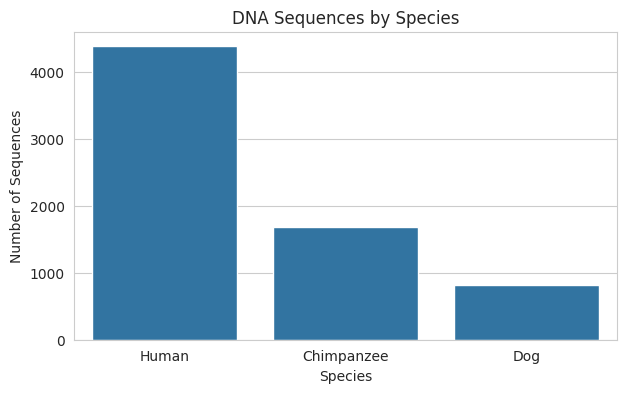

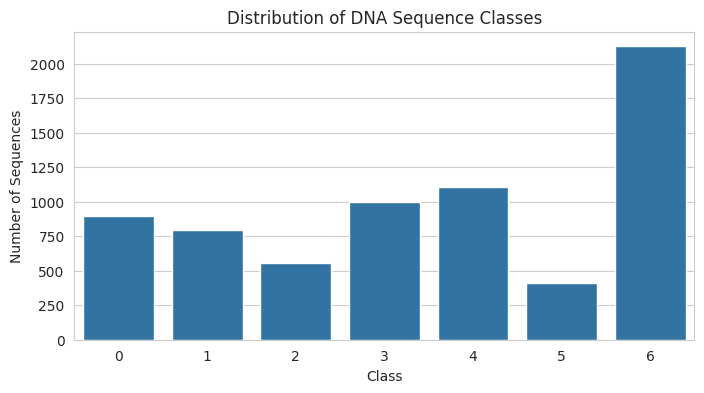

In [4]:

# Check the dataset
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

# Remove rows with missing sequence or class labels
data = data.dropna(subset=["sequence", "class"]).copy()

print("\nShape after removing missing values:", data.shape)

# Plot the number of sequences from each species
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="species")
plt.title("DNA Sequences by Species")
plt.xlabel("Species")
plt.ylabel("Number of Sequences")
plt.show()

# Plot the distribution of class labels
plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="class")
plt.title("Distribution of DNA Sequence Classes")
plt.xlabel("Class")
plt.ylabel("Number of Sequences")
plt.show()


## Step 5: DNA 4-Gram Feature Extraction

DNA sequences contain the nucleotides A, T, G, and C. In this step, we use character 4-grams to convert DNA sequences into numerical features that machine learning models can process. Each 4-gram represents a group of four consecutive characters.

In [5]:

from sklearn.feature_extraction.text import CountVectorizer

# Store DNA sequences and their class labels
X = data["sequence"].astype(str)
y = data["class"]

# Convert DNA sequences into character 4-gram features
vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(4, 4)
)

X_features = vectorizer.fit_transform(X)

print("Number of DNA sequences:", len(X))
print("Number of 4-gram features:", X_features.shape[1])
print("Feature matrix shape:", X_features.shape)

# Display some example 4-gram features
print("\nFirst 10 feature names:")
print(vectorizer.get_feature_names_out()[:10])


Number of DNA sequences: 6882
Number of 4-gram features: 371
Feature matrix shape: (6882, 371)

First 10 feature names:
['aaaa' 'aaac' 'aaag' 'aaat' 'aaca' 'aacc' 'aacg' 'aact' 'aaga' 'aagc']


## Step 6: Splitting the Dataset into Training and Testing Sets

In this step, we split the dataset into training and testing sets. We use 80% of the data for training and 20% for testing. The training data is used to train the machine learning models, while the testing data is used to evaluate their performance.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Select input and target
X = clean_data["sequence"].astype(str)
y = clean_data["class"]

# Split the data into training and testing sets
X_train_seq, X_test_seq, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Extract 4-gram features using training data only
vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(4, 4)
)

X_train = vectorizer.fit_transform(X_train_seq)
X_test = vectorizer.transform(X_test_seq)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data shape: (4896, 370)
Testing data shape: (1225, 370)
Training labels: (4896,)
Testing labels: (1225,)


## Step 7: Training Machine Learning Models

In this step, we convert DNA sequences into character 4-gram features using only the training data. We then train three machine learning models: Multinomial Naive Bayes, Logistic Regression, and Random Forest. These models will learn patterns from DNA sequences to predict their class labels.

In [29]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

print("\nAll models trained successfully.")

Multinomial Naive Bayes trained successfully!
Logistic Regression trained successfully!
Random Forest trained successfully!

All models trained successfully.


## Step 8: Model Evaluation and Comparison

In this step, we evaluate the performance of three machine learning models: Multinomial Naive Bayes, Logistic Regression, and Random Forest.

We use four evaluation metrics: Accuracy, Precision, Recall, and F1-Score. These metrics help us compare the classification performance of the models and identify which model performs best on the test dataset.

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.4204,0.4872,0.4296,0.4177
1,Logistic Regression,0.7616,0.7496,0.7337,0.7408
2,Random Forest,0.8678,0.9150,0.8286,0.8635


## Step 9: Confusion Matrix

In this step, we use confusion matrices to evaluate the classification performance of the three trained machine learning models. A confusion matrix shows the number of correct and incorrect predictions for each class. It helps us understand which classes are classified correctly and which classes are confused with one another.

Confusion Matrix: Multinomial Naive Bayes


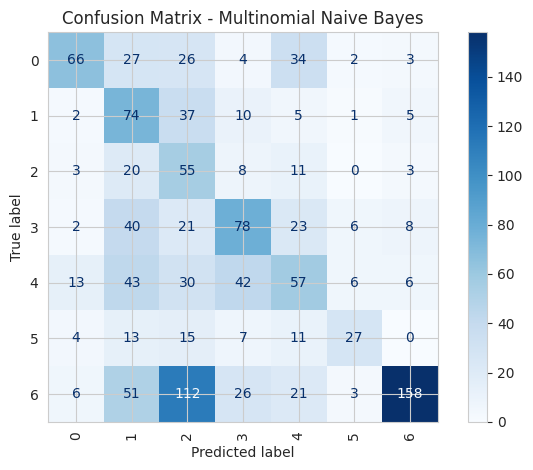

Confusion Matrix: Logistic Regression


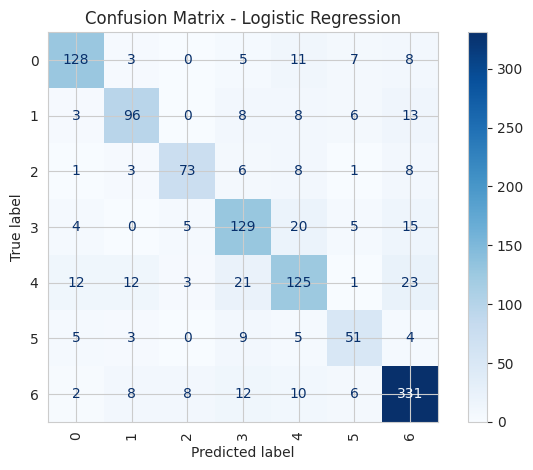

Confusion Matrix: Random Forest


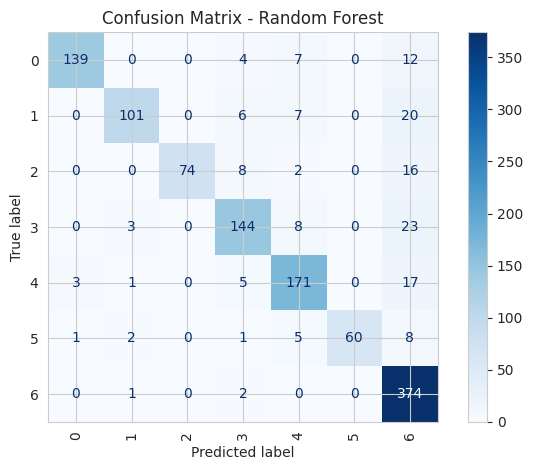

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    print("Confusion Matrix:", name)

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        cmap="Blues",
        xticks_rotation="vertical"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


### 10.1 Model Performance Comparison

This graph compares the Accuracy, Precision, Recall, and F1-Score of the three trained machine learning models. It helps identify the model with the best overall classification performance.


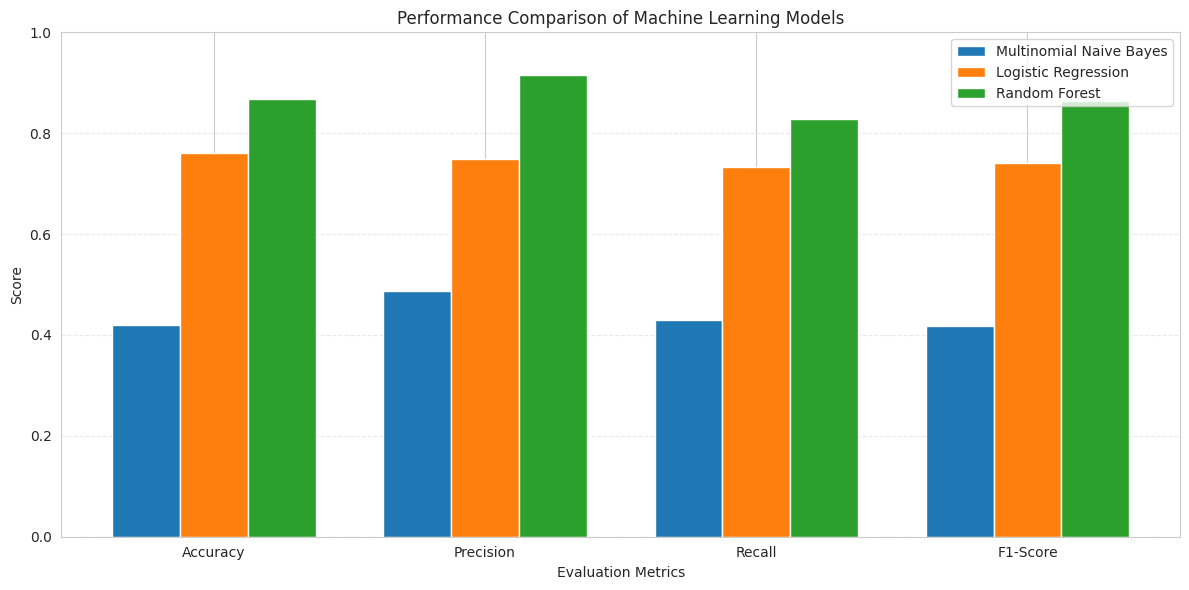

In [32]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
model_names = results_df["Model"].tolist()

values = results_df[metrics].values
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))

for i, name in enumerate(model_names):
    plt.bar(
        x + (i - 1) * width,
        values[i],
        width,
        label=name
    )

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Performance Comparison of Machine Learning Models")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()



### 10.2 Class Distribution

This graph shows the number of DNA sequence samples belonging to each target class in the cleaned dataset. It helps identify class imbalance in the dataset.


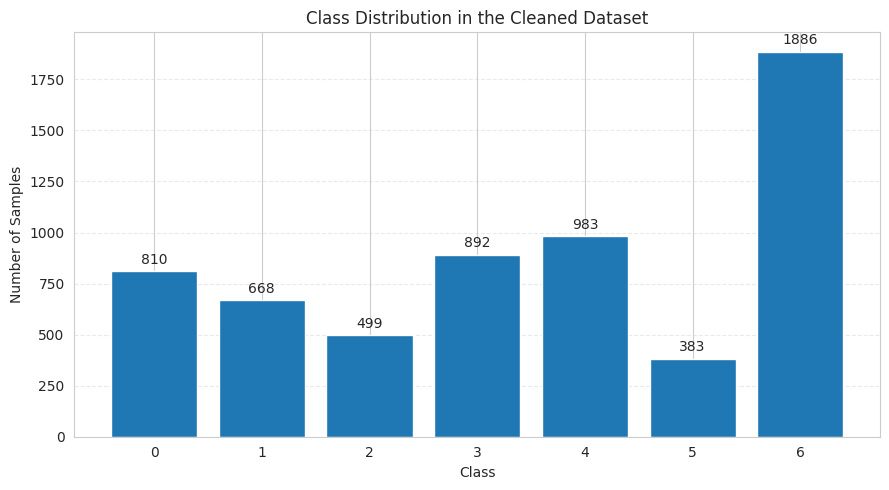

In [33]:
import matplotlib.pyplot as plt

class_counts = clean_data["class"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
bars = plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.bar_label(bars, padding=3)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution in the Cleaned Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
